# 🌧️ Ensemble Learning for Next-Day Heavy-Rainfall Prediction in Sri Lanka
### Bagging vs Boosting vs Stacking (+ a Random Forest + ANN Hybrid)

| | |
|---|---|
| **Student name** | `<Your Name>` |
| **Student ID** | `<Your ID>` |
| **Module** | Machine Learning – Ensemble Learning Assignment (10%) |
| **Deliverables** | This notebook · Streamlit dashboard (`app.py`) · 3-minute video |

> **Generative-AI disclosure:** this project was developed with help from a Generative-AI coding assistant (**Claude, by Anthropic, via Claude Code**). See the full statement in **Section 13** at the end of the notebook.

---
## 1. Problem statement

Sri Lanka's weather is driven by two monsoons, the **South-West monsoon (May–Sep)** and the **North-East monsoon (Dec–Feb)**, plus two inter-monsoon periods. Heavy rain during these seasons regularly causes **floods and landslides**, especially in Ratnapura, Kegalle, Colombo, Gampaha and the central hills. It also affects paddy cultivation in the Yala and Maha seasons.

**Goal:** using today's weather observations for a Sri Lankan city, predict whether that city will receive **heavy rainfall (≥ 10 mm) tomorrow**.

* **Type:** binary classification (`1` = heavy rain tomorrow, `0` = no heavy rain)
* **Why ensembles?** Weather is noisy and non-linear, and the interactions differ by region and season. Ensembles combine many models to reduce **variance** (bagging) and **bias** (boosting), or to merge **different kinds of learner** (stacking and hybrid models).
* **Why it matters locally:** a reliable next-day heavy-rain signal supports early flood and landslide warnings (as issued by the DMC and NBRO), irrigation planning, and farmers' decisions.

## 2. Setup and libraries

In [1]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import requests

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, StackingClassifier, VotingClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE  = 42
DATA_PATH     = Path("data/sri_lanka_weather_daily.csv")
MODEL_DIR     = Path("models"); MODEL_DIR.mkdir(exist_ok=True)
HEAVY_RAIN_MM = 10.0            # threshold for a "heavy rain" day (mm)
TEST_START    = "2025-01-01"    # chronological split: train 2016-2024, test 2025-2026
print("Ready ✔")

Ready ✔


## 3. Data acquisition: a local Sri Lankan dataset 🇱🇰

As the assignment requires, this project uses **only Sri Lankan data**. No foreign benchmark datasets are used.

* **Source:** the [**NASA POWER** API](https://power.larc.nasa.gov) (NASA Langley Research Center). It is free and needs no key. It provides daily weather from the **MERRA-2 reanalysis**, with **bias-corrected precipitation**, in local solar time.
* **Coverage:** **20 Sri Lankan towns**, at least one in **every one of the 9 provinces**, spanning the **Wet, Intermediate and Dry climatic zones**. NASA POWER data lies on a ≈ 50 km grid (0.5° × 0.625°), so the towns were chosen so that **each falls in a different grid cell**. The first version of the list contained Colombo/Gampaha and Kandy/Kegalle/Kurunegala, which turned out to share identical series, so they were replaced. The check below verifies this.
* **Period:** 1 Jan 2016 – 31 Oct 2026, daily (**79,140 town-days**).
* **Variables (15):** temperature (mean/max/min), **rainfall (mm)**, relative humidity, dew point, specific humidity, surface pressure, wind speed (mean/max), wind direction, solar radiation, **cloud cover**, and **topsoil / root-zone soil wetness** (relevant for flood and landslide risk).

The cell below downloads the data only if `data/sri_lanka_weather_daily.csv` is missing. The same code is also available as the stand-alone script `scripts/fetch_data.py`.

In [2]:
CITIES = [  # town, district, province, climatic zone, latitude, longitude
    ("Colombo","Colombo","Western","Wet",6.9271,79.8612),           ("Kalutara","Kalutara","Western","Wet",6.5854,79.9607),
    ("Kandy","Kandy","Central","Wet",7.2906,80.6337),                ("Nuwara Eliya","Nuwara Eliya","Central","Wet",6.9497,80.7891),
    ("Dambulla","Matale","Central","Dry",7.8742,80.6511),            ("Galle","Galle","Southern","Wet",6.0535,80.2210),
    ("Matara","Matara","Southern","Wet",5.9549,80.5550),             ("Hambantota","Hambantota","Southern","Dry",6.1241,81.1185),
    ("Ratnapura","Ratnapura","Sabaragamuwa","Wet",6.6828,80.3992),   ("Badulla","Badulla","Uva","Intermediate",6.9934,81.0550),
    ("Wellawaya","Monaragala","Uva","Intermediate",6.7372,81.1028),  ("Chilaw","Puttalam","North Western","Intermediate",7.5759,79.7953),
    ("Puttalam","Puttalam","North Western","Dry",8.0362,79.8283),    ("Anuradhapura","Anuradhapura","North Central","Dry",8.3114,80.4037),
    ("Polonnaruwa","Polonnaruwa","North Central","Dry",7.9403,81.0188), ("Trincomalee","Trincomalee","Eastern","Dry",8.5874,81.2152),
    ("Batticaloa","Batticaloa","Eastern","Dry",7.7310,81.6747),      ("Pottuvil","Ampara","Eastern","Dry",6.8767,81.8341),
    ("Jaffna","Jaffna","Northern","Dry",9.6615,80.0255),             ("Vavuniya","Vavuniya","Northern","Dry",8.7514,80.4971),
]
PARAMS = {"T2M": "temp_mean_c", "T2M_MAX": "temp_max_c", "T2M_MIN": "temp_min_c", "PRECTOTCORR": "rain_mm",
          "RH2M": "humidity_pct", "T2MDEW": "dew_point_c", "QV2M": "specific_humidity_gkg", "PS": "pressure_kpa",
          "WS10M": "wind_speed_ms", "WS10M_MAX": "wind_max_ms", "WD10M": "wind_dir_deg", "ALLSKY_SFC_SW_DWN": "solar_rad_mj",
          "CLOUD_AMT": "cloud_cover_pct", "GWETTOP": "soil_wetness_top", "GWETROOT": "soil_wetness_root"}

def download_city(name, district, province, zone, lat, lon):
    params = {"parameters": ",".join(PARAMS), "community": "AG", "latitude": lat, "longitude": lon,
              "start": "20160101", "end": "20261031", "format": "JSON", "time-standard": "LST"}
    r = requests.get("https://power.larc.nasa.gov/api/temporal/daily/point", params=params, timeout=180)
    r.raise_for_status(); js = r.json()
    d = pd.DataFrame(js["properties"]["parameter"]).rename(columns=PARAMS).replace(-999.0, np.nan)  # -999 = missing
    d.index = pd.to_datetime(d.index, format="%Y%m%d"); d = d.rename_axis("date").reset_index()
    d.insert(1, "city", name); d.insert(2, "district", district); d.insert(3, "province", province); d.insert(4, "climate_zone", zone)
    d["latitude"], d["longitude"], d["elevation"] = lat, lon, js["geometry"]["coordinates"][2]
    return d

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(exist_ok=True)
    frames = []
    for c in CITIES:
        print("downloading", c[0]); frames.append(download_city(*c)); time.sleep(1)
    pd.concat(frames).to_csv(DATA_PATH, index=False)

raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
print(f"Loaded {len(raw):,} rows × {raw.shape[1]} columns | {raw.city.nunique()} towns | {raw.province.nunique()} provinces | "
      f"{raw.date.min().date()} → {raw.date.max().date()}")
rc = raw.pivot(index="date", columns="city", values="rain_mm").corr()
dups = [(a, b) for i, a in enumerate(rc) for b in rc.columns[i + 1:] if rc.loc[a, b] > 0.999]
print("Towns sharing an identical rainfall series (same grid cell):", dups or "none ✔")
raw.head()

Loaded 79,140 rows × 23 columns | 20 towns | 9 provinces | 2016-01-01 → 2026-10-31
Towns sharing an identical rainfall series (same grid cell): none ✔


,date,city,district,province,climate_zone,temp_mean_c,temp_max_c,temp_min_c,rain_mm,humidity_pct,dew_point_c,specific_humidity_gkg,pressure_kpa,wind_speed_ms,wind_max_ms,wind_dir_deg,solar_rad_mj,cloud_cover_pct,soil_wetness_top,soil_wetness_root,latitude,longitude,elevation
0,2016-01-01,Colombo,Colombo,Western,Wet,26.23,29.44,23.94,2.10,85.88,23.62,18.37,99.91,5.90,6.55,25.1,16.09,59.41,0.86,0.89,6.9271,79.8612,123.66
1,2016-01-02,Colombo,Colombo,Western,Wet,26.03,29.46,23.55,2.31,85.98,23.41,18.15,99.97,4.99,5.67,31.3,17.78,54.84,0.86,0.88,6.9271,79.8612,123.66
2,2016-01-03,Colombo,Colombo,Western,Wet,25.78,29.44,22.95,0.55,84.84,22.94,17.64,99.92,5.76,7.32,30.4,22.03,29.61,0.85,0.88,6.9271,79.8612,123.66
3,2016-01-04,Colombo,Colombo,Western,Wet,26.31,30.02,23.28,0.47,85.14,23.53,18.30,99.89,5.26,6.51,20.7,22.18,35.09,0.85,0.87,6.9271,79.8612,123.66
4,2016-01-05,Colombo,Colombo,Western,Wet,26.56,29.62,24.26,4.14,87.20,24.20,19.05,99.82,4.64,5.39,11.8,20.19,56.22,0.85,0.86,6.9271,79.8612,123.66


## 4. Data cleaning and preprocessing

The steps are:
1. **Check duplicates** and sort each town's series by date.
2. **Handle missing values.** NASA POWER marks missing data with `-999`, which we convert to `NaN`. Cloud cover has **1,240 missing values**: the last 62 days (31 Aug – 31 Oct 2026) for every town, because NASA's satellite cloud product is published with a delay.
   * **Short internal gaps (≤ 3 days):** linear interpolation *within the same town's time series*. None occur here, but the step makes the pipeline robust to future data.
   * **Longer / trailing gaps:** filled with that town's **monthly climatology**, i.e. the median cloud cover for that town in that calendar month. This keeps the seasonal pattern instead of copying one stale value forward, which is how an operational system would also cope with a delayed data feed.
3. **Convert units:** surface pressure goes from kPa to **hPa** (the usual meteorological unit).
4. **Check physical ranges:** no negative rainfall, and humidity and cloud cover stay within 0–100%.

In [3]:
df = raw.copy()
print("Duplicate (town, date) rows:", df.duplicated(subset=["city", "date"]).sum())
df = df.drop_duplicates(subset=["city", "date"]).sort_values(["city", "date"]).reset_index(drop=True)

WEATHER_COLS = list(PARAMS.values())
miss = df[WEATHER_COLS].isna().sum()
print("\nMissing values per column (before):"); print(miss[miss > 0].to_string() if miss.sum() else "  none")

df[WEATHER_COLS] = df.groupby("city")[WEATHER_COLS].transform(lambda s: s.interpolate(limit=3, limit_area="inside"))
month = df.date.dt.month
for col in WEATHER_COLS:
    clim = df.groupby(["city", month])[col].transform("median")      # town × month climatology
    df[col] = df[col].fillna(clim)
df["pressure_hpa"] = df.pop("pressure_kpa") * 10
WEATHER_COLS = [c if c != "pressure_kpa" else "pressure_hpa" for c in WEATHER_COLS]

assert (df.rain_mm >= 0).all() and df.humidity_pct.between(0, 100).all() and df.cloud_cover_pct.between(0, 100).all()
print("\nMissing values after cleaning:", int(df[WEATHER_COLS].isna().sum().sum()), "✔")
df[WEATHER_COLS].describe().T.round(2)

Duplicate (town, date) rows: 0

Missing values per column (before):
cloud_cover_pct    1240



Missing values after cleaning: 0 ✔


,count,mean,std,min,25%,50%,75%,max
temp_mean_c,79140.0,26.76,1.84,18.08,25.72,26.93,28.00,32.46
temp_max_c,79140.0,29.74,2.20,21.27,28.28,29.34,30.95,40.27
temp_min_c,79140.0,24.55,2.35,12.48,23.14,25.05,26.27,30.55
rain_mm,79140.0,5.33,9.73,0.00,0.35,2.03,6.52,294.22
humidity_pct,79140.0,81.96,6.41,47.04,77.96,82.99,86.66,98.57
dew_point_c,79140.0,23.20,1.60,13.18,22.34,23.50,24.33,27.27
specific_humidity_gkg,79140.0,18.06,1.53,10.31,17.19,18.25,19.11,22.73
pressure_hpa,79140.0,994.50,18.08,930.00,992.90,1001.70,1005.60,1015.60
wind_speed_ms,79140.0,4.45,1.96,0.23,2.90,4.26,5.84,15.04
wind_max_ms,79140.0,5.86,2.17,0.44,4.17,5.72,7.41,19.58


## 5. Exploratory data analysis

### 5.1 Where it rains: the climatic zones of Sri Lanka

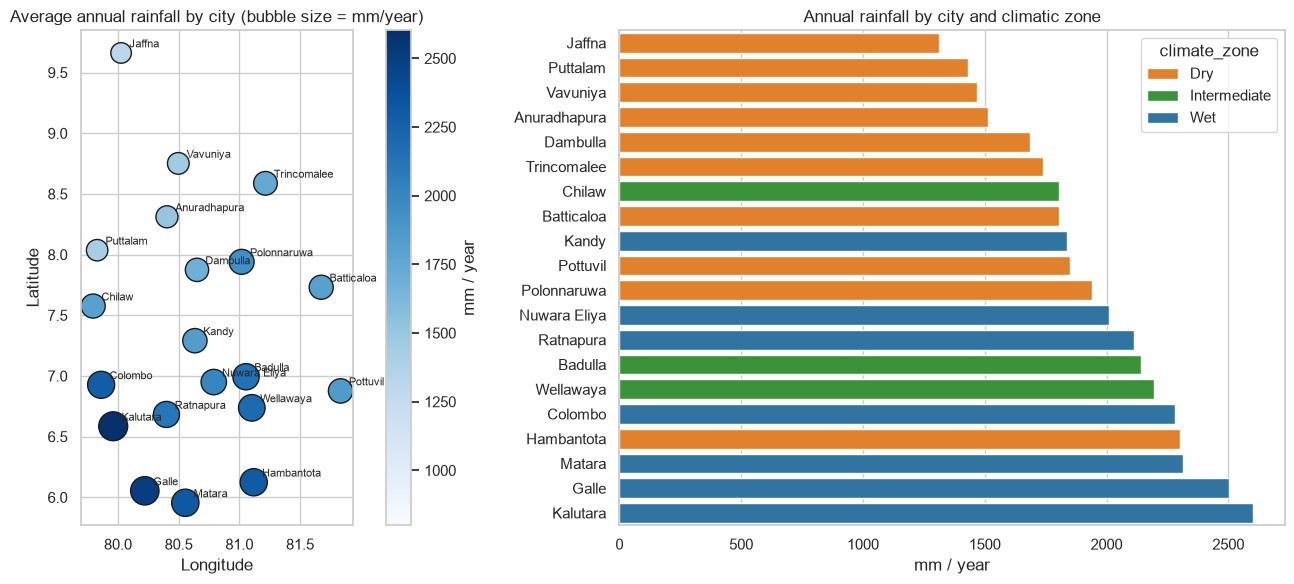

In [4]:
yearly = (df.assign(year=df.date.dt.year).query("year <= 2025")
            .groupby(["city", "year"]).rain_mm.sum().groupby("city").mean())
geo = df.groupby("city")[["latitude", "longitude", "climate_zone", "province"]].first().join(yearly.rename("annual_rain_mm"))

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sc = ax[0].scatter(geo.longitude, geo.latitude, s=geo.annual_rain_mm / 6, c=geo.annual_rain_mm, cmap="Blues",
                   edgecolor="k", vmin=800)
for c, r in geo.iterrows():
    ax[0].annotate(c, (r.longitude, r.latitude), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax[0].set(title="Average annual rainfall by city (bubble size = mm/year)", xlabel="Longitude", ylabel="Latitude")
ax[0].set_aspect("equal"); plt.colorbar(sc, ax=ax[0], label="mm / year")

order = geo.sort_values("annual_rain_mm").index
sns.barplot(x=geo.loc[order, "annual_rain_mm"], y=order, hue=geo.loc[order, "climate_zone"], dodge=False, ax=ax[1],
            palette={"Wet": "#1f77b4", "Intermediate": "#2ca02c", "Dry": "#ff7f0e"})
ax[1].set(title="Annual rainfall by city and climatic zone", xlabel="mm / year", ylabel="")
plt.tight_layout(); plt.show()

### 5.2 Monsoon seasonality

Average monthly rainfall by zone shows that every zone gets its heaviest rain in the **second inter-monsoon and NE monsoon (Oct–Dec)**. Only the **Wet zone** has a strong second peak in **May**, at the onset of the SW monsoon. The **Dry zone** is very dry from June to August because it lies in the rain shadow of the central hills during the SW monsoon.

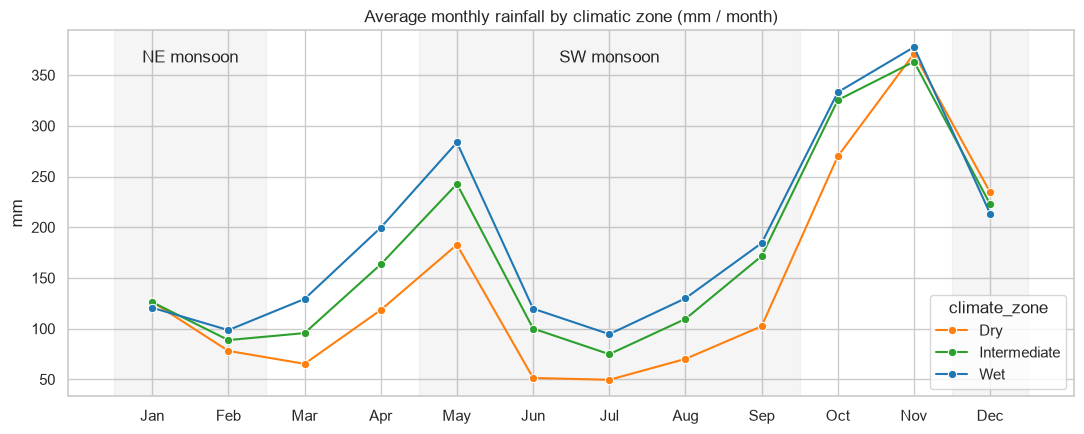

In [5]:
monthly = (df.assign(month=df.date.dt.month, year=df.date.dt.year)
             .groupby(["climate_zone", "city", "year", "month"]).rain_mm.sum()
             .groupby(["climate_zone", "month"]).mean().reset_index())
plt.figure(figsize=(11, 4.5))
sns.lineplot(data=monthly, x="month", y="rain_mm", hue="climate_zone", marker="o",
             palette={"Wet": "#1f77b4", "Intermediate": "#2ca02c", "Dry": "#ff7f0e"})
for (a, b, lab) in [(4.5, 9.5, "SW monsoon"), (0.5, 2.5, "NE monsoon"), (11.5, 12.5, "")]:
    plt.axvspan(a, b, alpha=.08, color="grey")
plt.text(7, plt.ylim()[1]*.92, "SW monsoon", ha="center"); plt.text(1.5, plt.ylim()[1]*.92, "NE monsoon", ha="center")
plt.xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
plt.title("Average monthly rainfall by climatic zone (mm / month)"); plt.ylabel("mm"); plt.xlabel("")
plt.tight_layout(); plt.show()

## 6. Feature engineering and target definition

All features use only information **available at the end of day *t***, and the target refers to **day *t + 1***. This avoids data leakage.

| Group | Features |
|---|---|
| **Today's weather** | temperature max/min/mean, rainfall (mm), relative and specific humidity, dew point, surface pressure, cloud cover, wind speed (mean/max), solar radiation |
| **Land-surface state** | topsoil and root-zone **soil wetness** (wet soils mean saturated catchments and persistent moisture recycling) |
| **Rainfall memory (lags)** | rain yesterday, rolling 3-day and 7-day rain totals, number of rainy days in the past week |
| **Change signals** | 1-day change in pressure (falling pressure → approaching systems) and in humidity |
| **Derived physics** | diurnal temperature range, dew-point depression (temperature − dew point; small = saturated air) |
| **Seasonality** | day-of-year encoded as sin/cos (cyclical) and **monsoon season** (NE, 1st inter-monsoon, SW, 2nd inter-monsoon) |
| **Location (local context)** | city, province, climatic zone, latitude, longitude, elevation |
| **Wind direction** | encoded as sin/cos so that 359° and 1° are close together |

**Target:** `heavy_rain_tomorrow = 1` if the next day's rainfall in the same city is **≥ 10 mm**, otherwise `0`.

In [6]:
def monsoon_season(month):
    return np.select([month.isin([12, 1, 2]), month.isin([3, 4]), month.isin([5, 6, 7, 8, 9])],
                     ["NE Monsoon", "First Inter-monsoon", "SW Monsoon"], default="Second Inter-monsoon")

def build_features(d):
    d = d.sort_values(["city", "date"]).copy()
    rain = d.groupby("city")["rain_mm"]
    d["rain_lag1"]    = rain.shift(1)
    d["rain_3d_sum"]  = rain.transform(lambda s: s.rolling(3, min_periods=3).sum())
    d["rain_7d_sum"]  = rain.transform(lambda s: s.rolling(7, min_periods=7).sum())
    d["rain_days_7d"] = rain.transform(lambda s: (s >= 1).rolling(7, min_periods=7).sum())
    d["pressure_change_1d"] = d.groupby("city")["pressure_hpa"].diff()
    d["humidity_change_1d"] = d.groupby("city")["humidity_pct"].diff()
    d["temp_range"]          = d["temp_max_c"] - d["temp_min_c"]
    d["dewpoint_depression"] = d["temp_mean_c"] - d["dew_point_c"]
    rad = np.deg2rad(d["wind_dir_deg"])
    d["wind_dir_sin"], d["wind_dir_cos"] = np.sin(rad), np.cos(rad)
    doy = d["date"].dt.dayofyear
    d["doy_sin"], d["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    d["monsoon_season"] = monsoon_season(d["date"].dt.month)
    # ---- TARGET: heavy rain TOMORROW in the same town ----
    d["rain_tomorrow_mm"] = rain.shift(-1)
    d["heavy_rain_tomorrow"] = np.where(d["rain_tomorrow_mm"].isna(), np.nan,
                                        (d["rain_tomorrow_mm"] >= HEAVY_RAIN_MM).astype(float))
    return d

CAT_FEATURES = ["city", "province", "climate_zone", "monsoon_season"]
NUM_FEATURES = ["latitude", "longitude", "elevation",
                "temp_max_c", "temp_min_c", "temp_mean_c", "temp_range",
                "rain_mm", "rain_lag1", "rain_3d_sum", "rain_7d_sum", "rain_days_7d",
                "humidity_pct", "humidity_change_1d", "dew_point_c", "dewpoint_depression", "specific_humidity_gkg",
                "pressure_hpa", "pressure_change_1d", "cloud_cover_pct",
                "wind_speed_ms", "wind_max_ms", "wind_dir_sin", "wind_dir_cos",
                "solar_rad_mj", "soil_wetness_top", "soil_wetness_root", "doy_sin", "doy_cos"]
FEATURES = NUM_FEATURES + CAT_FEATURES
TARGET = "heavy_rain_tomorrow"

feat = build_features(df)
model_df = feat.dropna(subset=NUM_FEATURES + [TARGET]).reset_index(drop=True)
model_df[TARGET] = model_df[TARGET].astype(int)
print(f"Modelling table: {model_df.shape[0]:,} rows | {len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical features")
print(f"Heavy-rain-tomorrow rate: {model_df[TARGET].mean():.1%}")

Modelling table: 79,000 rows | 29 numeric + 4 categorical features
Heavy-rain-tomorrow rate: 15.7%


### 6.1 Target distribution: the classes are **imbalanced**, and the imbalance varies strongly by region and month

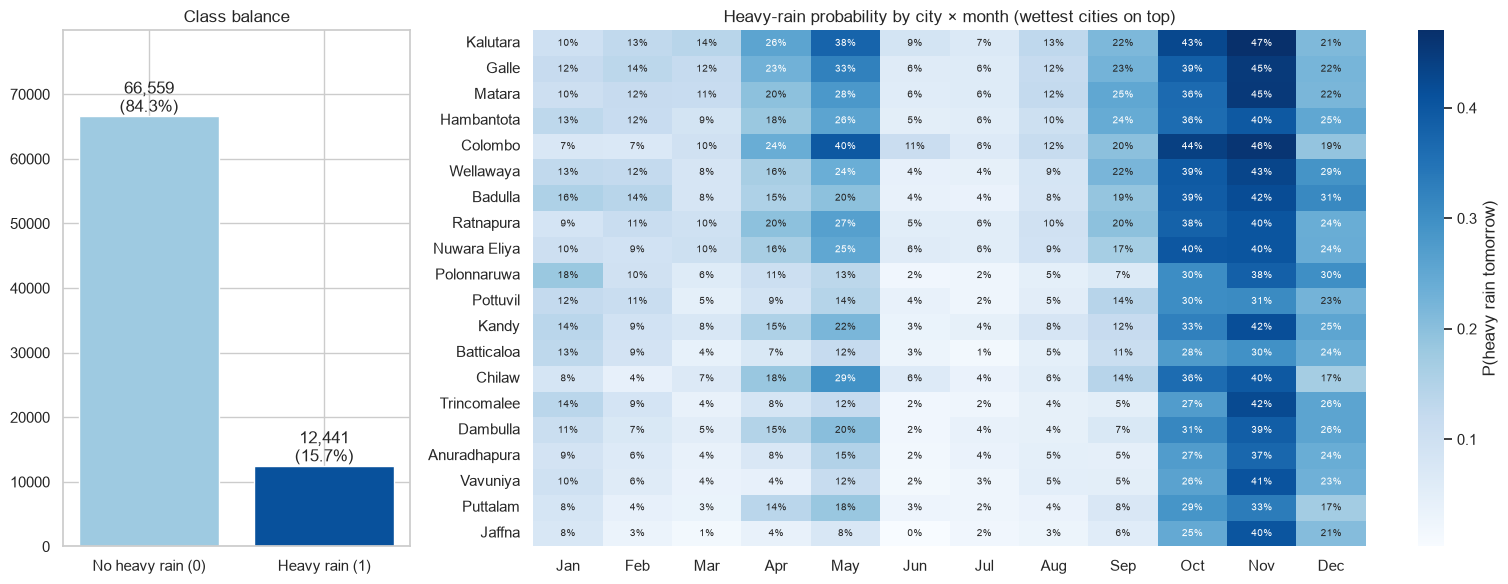

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 3]})
counts = model_df[TARGET].value_counts().sort_index()
ax[0].bar(["No heavy rain (0)", "Heavy rain (1)"], counts.values, color=["#9ecae1", "#08519c"])
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v:,}\n({v/counts.sum():.1%})", ha="center", va="bottom")
ax[0].set_title("Class balance"); ax[0].set_ylim(0, counts.max() * 1.2)

heat = (model_df.assign(month=model_df.date.dt.month).pivot_table(index="city", columns="month", values=TARGET, aggfunc="mean"))
heat = heat.loc[geo.sort_values("annual_rain_mm", ascending=False).index]
sns.heatmap(heat, cmap="Blues", annot=True, fmt=".0%", cbar_kws={"label": "P(heavy rain tomorrow)"}, ax=ax[1],
            xticklabels=["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], annot_kws={"size": 7})
ax[1].set(title="Heavy-rain probability by city × month (wettest cities on top)", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

### 6.2 Which single features are most related to tomorrow's heavy rain?

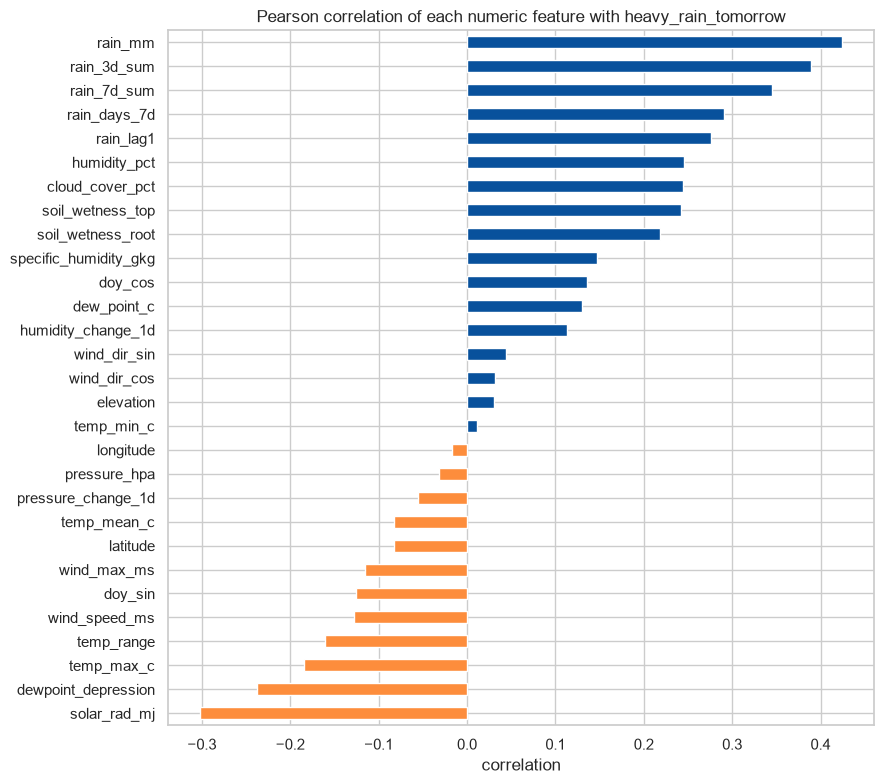

In [8]:
corr = model_df[NUM_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
plt.figure(figsize=(9, 8))
corr.plot.barh(color=np.where(corr > 0, "#08519c", "#fd8d3c"))
plt.title("Pearson correlation of each numeric feature with heavy_rain_tomorrow"); plt.xlabel("correlation")
plt.tight_layout(); plt.show()

## 7. Train/test split, encoding, scaling and class imbalance

* **Chronological split (no shuffling):** train on **2016–2024** and test on **Jan 2025 – Oct 2026**. A random split would let the model see "future" days that are highly correlated with the test days, which inflates the scores. A time-based split mirrors real forecasting.
* **Encoding:** one-hot encoding of the categorical features (city, province, climatic zone, monsoon season).
* **Scaling:** `StandardScaler` on the numeric features. Tree models do not need it, but logistic regression and the neural network do, so every model shares one preprocessing pipeline for a fair comparison.
* **Class imbalance:** we use **balanced sample weights** (`compute_sample_weight("balanced")`), so each heavy-rain day counts more during training. We chose class weighting over **SMOTE** because SMOTE would invent synthetic "weather days" by interpolating between real ones (physically unrealistic, and it would blur the time structure). Weighting achieves the same rebalancing without creating fake data, and it works for *every* model, including the stacking and voting ensembles.

In [9]:
train = model_df[model_df.date <  TEST_START]
test  = model_df[model_df.date >= TEST_START]
X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]
sw_train = compute_sample_weight("balanced", y_train)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUM_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
]).set_output(transform="pandas")

print(f"Train: {len(train):,} rows ({train.date.min().date()} → {train.date.max().date()}) | heavy-rain rate {y_train.mean():.1%}")
print(f"Test : {len(test):,} rows ({test.date.min().date()} → {test.date.max().date()}) | heavy-rain rate {y_test.mean():.1%}")
print(f"Sample weights → class 0: {sw_train[y_train.values == 0][0]:.2f}, class 1: {sw_train[y_train.values == 1][0]:.2f}")
print("Model input width after one-hot encoding:", preprocessor.fit(X_train).transform(X_train.head()).shape[1], "columns")

Train: 65,640 rows (2016-01-07 → 2024-12-31) | heavy-rain rate 15.3%
Test : 13,360 rows (2025-01-01 → 2026-10-30) | heavy-rain rate 17.7%
Sample weights → class 0: 0.59, class 1: 3.26
Model input width after one-hot encoding: 65 columns


### Evaluation helper

All models go through the **same** pipeline (`preprocessing → model`) and are trained with the same sample weights. They are evaluated on the same 2025–26 test set with:

* **Accuracy**: overall correctness. It can be misleading with imbalanced classes.
* **Precision**: when we warn "heavy rain", how often are we right? (false alarms)
* **Recall**: of all real heavy-rain days, how many did we catch? (missed events, which matter most for flood warnings)
* **F1-score**: the harmonic mean of precision and recall. This is our **primary metric**.
* **ROC-AUC / PR-AUC**: threshold-independent ranking quality.

In [10]:
results, fitted, probas = [], {}, {}

def evaluate(name, family, estimator):
    pipe = Pipeline([("prep", clone(preprocessor)), ("model", estimator)])
    t0 = time.time()
    pipe.fit(X_train, y_train, model__sample_weight=sw_train)
    secs = time.time() - t0
    p = pipe.predict_proba(X_test)[:, 1]; yhat = (p >= 0.5).astype(int)
    row = dict(model=name, family=family,
               accuracy=accuracy_score(y_test, yhat), precision=precision_score(y_test, yhat),
               recall=recall_score(y_test, yhat), f1=f1_score(y_test, yhat),
               roc_auc=roc_auc_score(y_test, p), pr_auc=average_precision_score(y_test, p), train_time_s=secs)
    results[:] = [r for r in results if r["model"] != name] + [row]
    fitted[name], probas[name] = pipe, p
    print(f"{name:<34} acc={row['accuracy']:.3f}  prec={row['precision']:.3f}  rec={row['recall']:.3f}  "
          f"F1={row['f1']:.3f}  AUC={row['roc_auc']:.3f}  ({secs:.1f}s)")
    return pipe

## 8. Models

### 8.0 Baselines (single models)
These give a reference point: an ensemble is only worth its extra complexity if it beats them.

In [11]:
evaluate("Logistic Regression", "Baseline", LogisticRegression(max_iter=3000, C=1.0))
evaluate("Decision Tree", "Baseline", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=RANDOM_STATE))
ANN = MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, batch_size=256, learning_rate_init=1e-3,
                    max_iter=200, early_stopping=True, n_iter_no_change=8, random_state=RANDOM_STATE)
evaluate("Neural Network (ANN)", "Baseline", ANN);

Logistic Regression                acc=0.781  prec=0.433  rec=0.762  F1=0.553  AUC=0.854  (1.2s)


Decision Tree                      acc=0.759  prec=0.406  rec=0.781  F1=0.535  AUC=0.843  (1.2s)


Neural Network (ANN)               acc=0.756  prec=0.407  rec=0.812  F1=0.542  AUC=0.857  (6.4s)


### 8.1 🌲 Bagging (Bootstrap Aggregating): Random Forest and Extra Trees

**Idea:** train many deep decision trees **in parallel**. Each tree sees a different **bootstrap sample** of the rows, and at every split a **random subset of features** (`max_features="sqrt"`). The final prediction is the **average vote** of the trees.

* A single deep tree has **low bias but high variance**: it overfits noise in the weather data.
* Averaging many *de-correlated* trees keeps the low bias and **greatly reduces the variance**.
* **Out-of-Bag (OOB) score:** each tree is trained on a bootstrap sample, so it never sees some of the rows: about 37% with a full-size bootstrap, and about half here because `max_samples=0.7`. Those unseen rows act as a free built-in validation set.
* **Extra Trees** go further: they also pick split thresholds at random, which adds even more randomness and lowers variance further.

In [12]:
RF = RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=10, max_samples=0.7,
                            oob_score=True, n_jobs=-1, random_state=RANDOM_STATE)
rf_pipe = evaluate("Random Forest", "Bagging", RF)
print(f"   Random Forest Out-of-Bag accuracy (built-in validation): {rf_pipe.named_steps['model'].oob_score_:.3f}")

ET = ExtraTreesClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=10, n_jobs=-1, random_state=RANDOM_STATE)
evaluate("Extra Trees", "Bagging", ET);

Random Forest                      acc=0.820  prec=0.494  rec=0.669  F1=0.568  AUC=0.862  (13.0s)
   Random Forest Out-of-Bag accuracy (built-in validation): 0.851


Extra Trees                        acc=0.778  prec=0.427  rec=0.743  F1=0.542  AUC=0.849  (5.8s)


**How many trees do we need?** The OOB error falls quickly and then levels off. Adding trees never causes overfitting in bagging; it only stabilises the average.

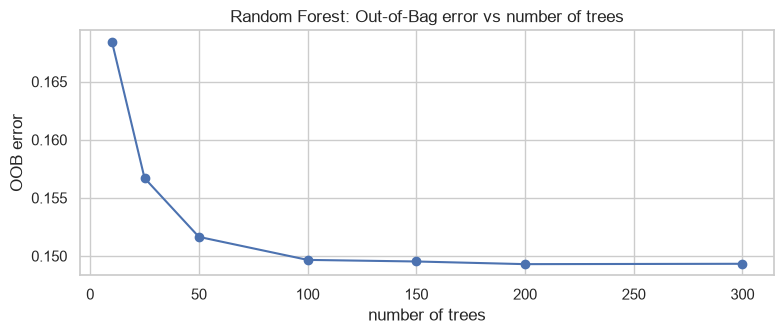

In [13]:
Xt_train = rf_pipe.named_steps["prep"].transform(X_train)
oob_curve = []
rf_ws = RandomForestClassifier(max_features="sqrt", min_samples_leaf=10, max_samples=0.7, oob_score=True,
                               warm_start=True, n_jobs=-1, random_state=RANDOM_STATE)
for n in [10, 25, 50, 100, 150, 200, 300]:
    rf_ws.set_params(n_estimators=n).fit(Xt_train, y_train, sample_weight=sw_train)
    oob_curve.append((n, 1 - rf_ws.oob_score_))
oob_curve = pd.DataFrame(oob_curve, columns=["trees", "oob_error"])
ax = oob_curve.plot(x="trees", y="oob_error", marker="o", figsize=(8, 3.5), legend=False)
ax.set(title="Random Forest: Out-of-Bag error vs number of trees", ylabel="OOB error", xlabel="number of trees")
plt.tight_layout(); plt.show()

### 8.2 🚀 Boosting: AdaBoost, Gradient Boosting, XGBoost, LightGBM and CatBoost

**Idea:** train **shallow** trees **sequentially**. Each new tree focuses on the mistakes of the ensemble built so far, which reduces **bias** step by step.

| Algorithm | How it corrects errors | Notes |
|---|---|---|
| **AdaBoost** | Re-weights misclassified days, so the next weak learner focuses on them | depth-2 trees, weighted vote |
| **Gradient Boosting (GBM)** | Fits each tree to the **gradient of the log-loss** (the residual errors) | classic scikit-learn version |
| **XGBoost** | Gradient boosting + **L1/L2 regularisation**, second-order gradients and histogram splits | fast and robust |
| **LightGBM** | **Leaf-wise** tree growth + histogram binning | very fast on large tabular data |
| **CatBoost** | **Ordered boosting** + symmetric trees | strong out-of-the-box and less overfitting |

We use a small learning rate with many trees, plus row/column subsampling, which regularises the boosting process.

In [14]:
evaluate("AdaBoost", "Boosting",
         AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=200, learning_rate=0.5,
                            random_state=RANDOM_STATE))
evaluate("Gradient Boosting", "Boosting",
         GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.8,
                                    random_state=RANDOM_STATE))
evaluate("XGBoost", "Boosting",
         XGBClassifier(n_estimators=500, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                       reg_lambda=1.0, tree_method="hist", eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE))
LGBM = LGBMClassifier(n_estimators=500, num_leaves=31, learning_rate=0.05, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, importance_type="gain", random_state=RANDOM_STATE, verbose=-1)
evaluate("LightGBM", "Boosting", LGBM)
evaluate("CatBoost", "Boosting",
         CatBoostClassifier(iterations=600, depth=6, learning_rate=0.05, random_seed=RANDOM_STATE, verbose=0,
                            thread_count=-1));

AdaBoost                           acc=0.756  prec=0.407  rec=0.819  F1=0.544  AUC=0.859  (50.6s)


Gradient Boosting                  acc=0.768  prec=0.419  rec=0.803  F1=0.551  AUC=0.863  (58.5s)


XGBoost                            acc=0.785  prec=0.440  rec=0.764  F1=0.558  AUC=0.863  (5.0s)


LightGBM                           acc=0.791  prec=0.446  rec=0.735  F1=0.555  AUC=0.861  (4.4s)


CatBoost                           acc=0.785  prec=0.439  rec=0.764  F1=0.558  AUC=0.863  (15.9s)


**Boosting learns sequentially.** The test ROC-AUC improves as trees are added (each tree corrects the previous ones). AdaBoost's progress levels off earlier than gradient boosting's.

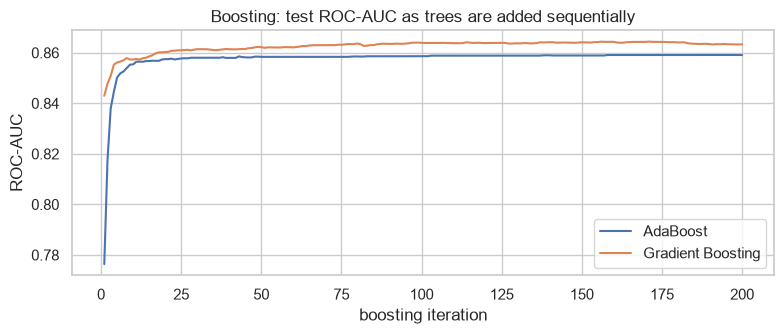

In [15]:
Xt_test = fitted["Gradient Boosting"].named_steps["prep"].transform(X_test)
curves = {}
for name in ["AdaBoost", "Gradient Boosting"]:
    m = fitted[name].named_steps["model"]
    curves[name] = [roc_auc_score(y_test, p[:, 1]) for p in m.staged_predict_proba(Xt_test)]
plt.figure(figsize=(8, 3.5))
for name, c in curves.items():
    plt.plot(range(1, len(c) + 1), c, label=name)
plt.title("Boosting: test ROC-AUC as trees are added sequentially"); plt.xlabel("boosting iteration"); plt.ylabel("ROC-AUC")
plt.legend(); plt.tight_layout(); plt.show()

### 8.3 🧱 Stacking (meta-learning)

**Idea:** combine **different kinds** of model (heterogeneous base learners) and let a **meta-model** learn how much to trust each one.

```
Level-0 base learners             Level-1 meta-learner
 ├─ Random Forest   (bagging)  ─┐
 ├─ LightGBM        (boosting) ─┼─► out-of-fold probabilities ─► Logistic Regression ─► final probability
 └─ Neural Network  (ANN)      ─┘
```

* The base learners make **different kinds of error**: RF averages deep trees, LightGBM corrects bias sequentially, and the ANN learns smooth non-linear functions.
* To prevent **data leakage**, the meta-learner is trained on **5-fold out-of-fold predictions**. It never sees a base model's prediction for a row that base model was trained on.

In [16]:
stack = StackingClassifier(
    estimators=[("rf", clone(RF).set_params(oob_score=False)), ("lgbm", clone(LGBM)), ("ann", clone(ANN))],
    final_estimator=LogisticRegression(max_iter=2000),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    stack_method="predict_proba")
stack_pipe = evaluate("Stacking (RF+LGBM+ANN→LR)", "Stacking", stack)

meta = stack_pipe.named_steps["model"].final_estimator_
print("\nMeta-learner (logistic regression) weights given to each base model:")
for (n, _), w in zip(stack_pipe.named_steps["model"].estimators, meta.coef_[0]):
    print(f"   {n:<5} → {w:+.3f}")

Stacking (RF+LGBM+ANN→LR)          acc=0.779  prec=0.430  rec=0.761  F1=0.550  AUC=0.859  (106.3s)

Meta-learner (logistic regression) weights given to each base model:
   rf    → -0.785
   lgbm  → +6.829
   ann   → -0.233


### 8.4 🔀 Hybrid model: Random Forest + Artificial Neural Network

The assignment encourages a **hybrid** that couples two *different model families*. We combine:
* a **Random Forest**: non-parametric, axis-aligned decision boundaries, robust to outliers.
* an **ANN (multi-layer perceptron, 64→32 ReLU)**: smooth, distributed representations that can model gradual interactions (for example humidity × pressure × season).

The hybrid is a **soft-voting** ensemble that averages the two models' predicted probabilities. It works when the two models are **accurate but not perfectly correlated**, because their errors partly cancel out.

In [17]:
hybrid = VotingClassifier([("rf", clone(RF).set_params(oob_score=False)), ("ann", clone(ANN))], voting="soft")
evaluate("Hybrid RF + ANN", "Hybrid", hybrid)
r = np.corrcoef(probas["Random Forest"], probas["Neural Network (ANN)"])[0, 1]
print(f"\nCorrelation between RF and ANN test probabilities: {r:.3f}  (< 1 ⇒ they make partly different errors)")
pd.DataFrame(results).set_index("model").loc[["Random Forest", "Neural Network (ANN)", "Hybrid RF + ANN"],
                                             ["f1", "roc_auc", "recall", "precision"]].round(3)

Hybrid RF + ANN                    acc=0.788  prec=0.444  rec=0.766  F1=0.562  AUC=0.863  (18.2s)

Correlation between RF and ANN test probabilities: 0.940  (< 1 ⇒ they make partly different errors)


,f1,roc_auc,recall,precision
model,,,,
Random Forest,0.568,0.862,0.669,0.494
Neural Network (ANN),0.542,0.857,0.812,0.407
Hybrid RF + ANN,0.562,0.863,0.766,0.444


## 9. Model comparison: Bagging vs Boosting vs Stacking vs Hybrid

In [18]:
res = (pd.DataFrame(results).sort_values("f1", ascending=False).reset_index(drop=True))
res.index = res.index + 1
best_name = res.iloc[0]["model"]
(res.style.format({c: "{:.3f}" for c in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]} | {"train_time_s": "{:.1f}"})
    .background_gradient(subset=["f1", "roc_auc", "pr_auc"], cmap="Greens")
    .set_caption("Test-set performance (Jan 2025 – Oct 2026), sorted by F1"))

,model,family,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_s
1,Random Forest,Bagging,0.820,0.494,0.669,0.568,0.862,0.597,13.0
2,Hybrid RF + ANN,Hybrid,0.788,0.444,0.766,0.562,0.863,0.600,18.2
3,XGBoost,Boosting,0.785,0.440,0.764,0.558,0.863,0.595,5.0
4,CatBoost,Boosting,0.785,0.439,0.764,0.558,0.863,0.588,15.9
5,LightGBM,Boosting,0.791,0.446,0.735,0.555,0.861,0.590,4.4
6,Logistic Regression,Baseline,0.781,0.433,0.762,0.553,0.854,0.559,1.2
7,Gradient Boosting,Boosting,0.768,0.419,0.803,0.551,0.863,0.591,58.5
8,Stacking (RF+LGBM+ANN→LR),Stacking,0.779,0.430,0.761,0.550,0.859,0.579,106.3
9,AdaBoost,Boosting,0.756,0.407,0.819,0.544,0.859,0.574,50.6
10,Extra Trees,Bagging,0.778,0.427,0.743,0.542,0.849,0.572,5.8


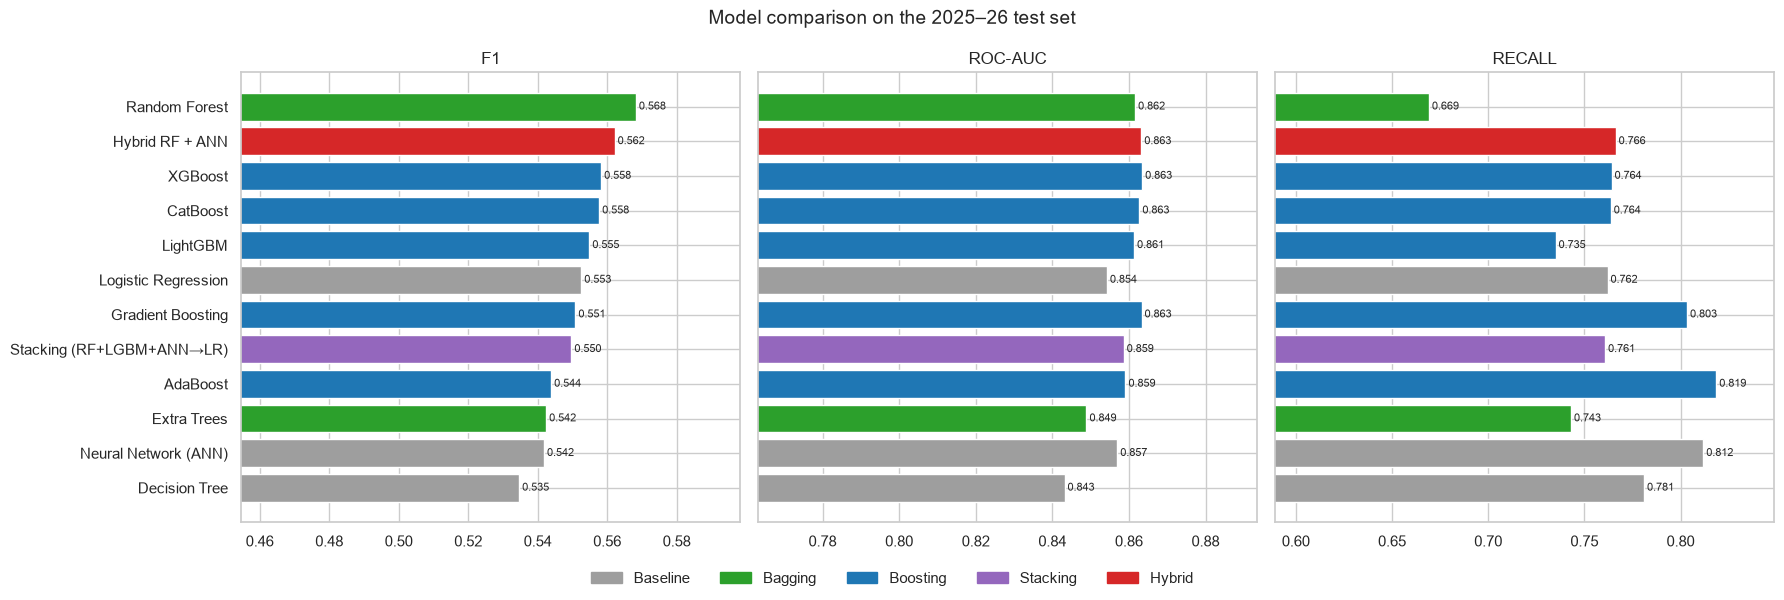

Average by ensemble family:


,accuracy,precision,recall,f1,roc_auc
family,,,,,
Hybrid,0.788,0.444,0.766,0.562,0.863
Bagging,0.799,0.460,0.706,0.555,0.855
Boosting,0.777,0.430,0.777,0.553,0.862
Stacking,0.779,0.430,0.761,0.550,0.859
Baseline,0.765,0.415,0.785,0.543,0.851


In [19]:
FAM_COLORS = {"Baseline": "#9e9e9e", "Bagging": "#2ca02c", "Boosting": "#1f77b4", "Stacking": "#9467bd", "Hybrid": "#d62728"}
fig, ax = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
r_sorted = res.sort_values("f1")
for a, metric in zip(ax, ["f1", "roc_auc", "recall"]):
    a.barh(r_sorted.model, r_sorted[metric], color=r_sorted.family.map(FAM_COLORS))
    lo = r_sorted[metric].min()
    a.set_xlim(max(0, lo - 0.08), min(1, r_sorted[metric].max() + 0.03))
    for y, v in enumerate(r_sorted[metric]): a.text(v, y, f" {v:.3f}", va="center", fontsize=8)
    a.set_title(metric.upper().replace("_", "-"))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAM_COLORS.values()]
fig.legend(handles, FAM_COLORS.keys(), loc="lower center", ncol=5, frameon=False)
plt.suptitle("Model comparison on the 2025–26 test set", fontsize=14); plt.tight_layout(rect=(0, .05, 1, 1)); plt.show()

print("Average by ensemble family:")
display(res.groupby("family")[["accuracy", "precision", "recall", "f1", "roc_auc"]].mean()
           .sort_values("f1", ascending=False).round(3))

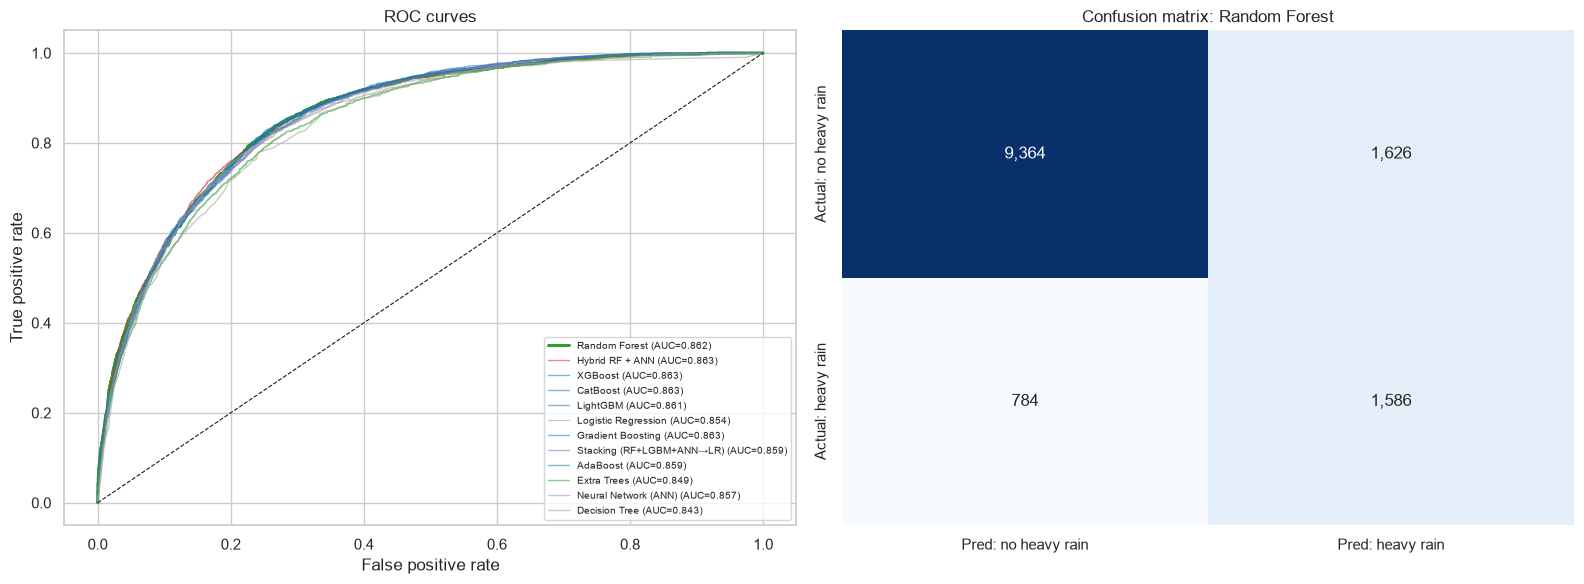

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
show = list(res.model)
for name in show:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    fam = res.set_index("model").loc[name, "family"]
    ax[0].plot(fpr, tpr, lw=2.2 if name == best_name else 1, color=FAM_COLORS[fam], alpha=1 if name == best_name else .55,
               label=f"{name} (AUC={roc_auc_score(y_test, probas[name]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate")
ax[0].legend(fontsize=7.5, loc="lower right")

cm = confusion_matrix(y_test, (probas[best_name] >= .5).astype(int))
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax[1],
            xticklabels=["Pred: no heavy rain", "Pred: heavy rain"], yticklabels=["Actual: no heavy rain", "Actual: heavy rain"])
ax[1].set_title(f"Confusion matrix: {best_name}")
plt.tight_layout(); plt.show()

### 9.1 Feature importance: what drives tomorrow's heavy rain?
Tree models report impurity- or gain-based importance. For the ANN, stacking and hybrid models we use **permutation importance**: shuffle one feature and measure how much ROC-AUC drops. One-hot columns are summed back to their original feature (for example all `city_*` columns → `city`).

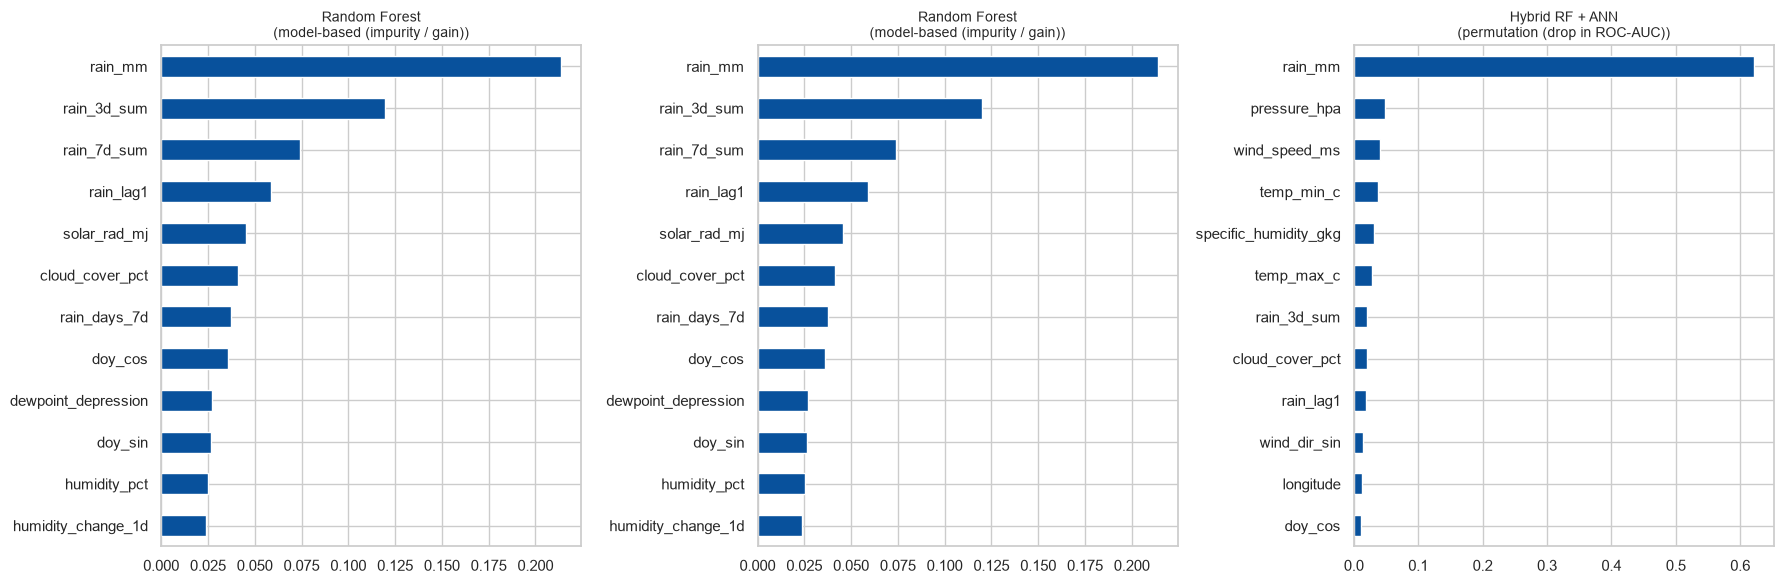

In [21]:
def aggregate_to_raw(names, values):
    out = {}
    for n, v in zip(names, values):
        base = n.split("__", 1)[1]
        raw_name = next((c for c in CAT_FEATURES if base.startswith(c + "_")), base)
        out[raw_name] = out.get(raw_name, 0) + float(v)
    s = pd.Series(out).clip(lower=0)
    return (s / s.sum()).sort_values(ascending=False)

importances = {}
perm_sample = test.sample(3000, random_state=RANDOM_STATE)
for name, pipe in fitted.items():
    m, names = pipe.named_steps["model"], pipe.named_steps["prep"].get_feature_names_out()
    if hasattr(m, "feature_importances_"):
        importances[name] = ("model-based (impurity / gain)", aggregate_to_raw(names, m.feature_importances_))
    elif isinstance(m, LogisticRegression):
        importances[name] = ("|standardised coefficient|", aggregate_to_raw(names, np.abs(m.coef_[0])))
    else:
        pi = permutation_importance(pipe, perm_sample[FEATURES], perm_sample[TARGET], scoring="roc_auc",
                                    n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
        s = pd.Series(pi.importances_mean, index=FEATURES).clip(lower=0)
        importances[name] = ("permutation (drop in ROC-AUC)", (s / s.sum()).sort_values(ascending=False))

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, name in zip(ax, [best_name, "Random Forest", "Hybrid RF + ANN" if best_name != "Hybrid RF + ANN" else "XGBoost"]):
    method, s = importances[name]
    s.head(12)[::-1].plot.barh(ax=a, color="#08519c")
    a.set_title(f"{name}\n({method})", fontsize=10)
plt.tight_layout(); plt.show()

### 9.2 Does performance differ across Sri Lanka's climatic zones and seasons? (best model)

In [22]:
best_pred = (probas[best_name] >= .5).astype(int)
tz = test.assign(pred=best_pred, proba=probas[best_name])
def group_scores(g):
    return pd.Series({"days": len(g), "heavy_rain_rate": g[TARGET].mean(), "f1": f1_score(g[TARGET], g.pred),
                      "recall": recall_score(g[TARGET], g.pred), "roc_auc": roc_auc_score(g[TARGET], g.proba)})
by_zone   = tz.groupby("climate_zone").apply(group_scores).round(3)
by_season = tz.groupby("monsoon_season").apply(group_scores).round(3)
display(by_zone); display(by_season)

,days,heavy_rain_rate,f1,recall,roc_auc
climate_zone,,,,,
Dry,6680.0,0.141,0.553,0.657,0.882
Intermediate,2004.0,0.203,0.592,0.703,0.847
Wet,4676.0,0.219,0.574,0.667,0.834


,days,heavy_rain_rate,f1,recall,roc_auc
monsoon_season,,,,,
First Inter-monsoon,2440.0,0.158,0.466,0.561,0.802
NE Monsoon,2980.0,0.173,0.450,0.533,0.799
SW Monsoon,6120.0,0.103,0.482,0.517,0.870
Second Inter-monsoon,1820.0,0.461,0.739,0.917,0.826


## 10. Interpretation: why did this model perform best?

*(The cell below prints the ranking from the actual run. The discussion that follows interprets it.)*

In [23]:
fam_best = res.loc[res.groupby("family")["f1"].idxmax(), ["family", "model", "f1", "roc_auc", "recall", "precision"]]
print("Best model overall:", best_name)
print(res.iloc[0][["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].astype(float).round(3).to_string())
print("\nBest model within each family:")
print(fam_best.sort_values("f1", ascending=False).round(3).to_string(index=False))

Best model overall: Random Forest
accuracy     0.820
precision    0.494
recall       0.669
f1           0.568
roc_auc      0.862
pr_auc       0.597

Best model within each family:
  family                     model    f1  roc_auc  recall  precision
 Bagging             Random Forest 0.568    0.862   0.669      0.494
  Hybrid           Hybrid RF + ANN 0.562    0.863   0.766      0.444
Boosting                   XGBoost 0.558    0.863   0.764      0.440
Baseline       Logistic Regression 0.553    0.854   0.762      0.433
Stacking Stacking (RF+LGBM+ANN→LR) 0.550    0.859   0.761      0.430


### 10.1 Key findings

1. **Every ensemble beats the single decision tree.** F1 rises from **0.535** (one tree) to **0.568** (Random Forest), and ROC-AUC from **0.843** to **≈ 0.863**. Averaging many trees removes most of a single tree's variance.
2. **The winner depends on the metric, and the margins are small:**
   * 🥇 **Random Forest (Bagging)** has the best **F1 (0.568)**, **accuracy (0.820)** and **precision (0.494)**.
   * **XGBoost, Gradient Boosting (Boosting) and the Hybrid RF + ANN** share the best **ROC-AUC (≈ 0.863)**, and the **Hybrid** has the best **PR-AUC (0.600)**.
   * The top eight models are within ≈ 0.02 F1 of each other, and all nine tree ensembles lie between 0.849 and 0.863 ROC-AUC. The ceiling is set mainly by the information in daily, ~50 km reanalysis data, not by the choice of ensemble.

### 10.2 Why did the Random Forest (Bagging) win on F1?

* **A noisy target rewards variance reduction.** Whether a town gets ≥ 10 mm tomorrow depends partly on short-lived convective storms that daily averages cannot see. From the features' point of view, many labels are effectively noise.
  * **Bagging averages this noise away.** It trains 300 de-correlated trees on bootstrap samples.
  * **Boosting keeps re-focusing on the hardest, often unpredictable days.** **AdaBoost**, which explicitly up-weights misclassified days, has the **lowest precision (0.407)** of all the ensembles.
* **It has a better-balanced operating point.** With balanced class weights, the boosted models (which minimise weighted log-loss) push many borderline days above the 0.5 threshold.
  * Boosting therefore gets **high recall (0.74–0.82) but more false alarms** (precision 0.41–0.45).
  * The Random Forest's probabilities are averages over 300 trees whose leaves hold at least 10 days each, so they are **smoother and more conservative**. At 0.5 it trades some recall (0.669) for many fewer false alarms, which gives the best F1.
  * On threshold-free ranking (ROC-AUC), boosting is marginally better (+0.002). Boosting's strength here is *ranking* days, not the default decision threshold.
* **Feature randomisation helps with correlated predictors.** Rain today, the 3- and 7-day totals, humidity, dew point and cloud cover are strongly correlated. `max_features="sqrt"` makes the trees use different feature subsets, which de-correlates their errors.
  * The **out-of-bag accuracy (0.851)** gave a free validation estimate.
  * Test accuracy is a little lower (0.820) because **2025–26 was wetter** than the training years (17.7% vs 15.3% heavy-rain days), which is a mild distribution shift.

### 10.3 Why didn't Stacking win?
The logistic-regression meta-learner put almost all its weight on **LightGBM (+6.83)**, with small *negative* weights on the **RF (−0.79)** and the **ANN (−0.23)**.
* The base models are **highly correlated** (RF vs ANN probabilities: r = 0.94), because all of them rely on the same dominant signal, today's rain. There was little complementary information left for the meta-learner to exploit.
* The extra layer added variance. Stacking pays off when base learners make **different** errors, and here they mostly agree.

### 10.4 Why did the Hybrid RF + ANN do well?
Averaging the conservative RF with the high-recall ANN produced a middle operating point (**F1 0.562, 2nd overall**). It also gave the **best PR-AUC (0.600)** and a **ROC-AUC (0.863) higher than either parent** (RF 0.862, ANN 0.857). Combining two *different model families* improved how heavy-rain days are ranked, which is exactly the motivation for hybridisation.

### 10.5 What drives the predictions? (feature importance)
* **All models agree that rain today is the strongest predictor.** Monsoon wet spells persist, so a wet day is usually followed by another.
* Next come the **3- and 7-day rainfall totals** (wet-spell memory), **seasonality** (day-of-year, monsoon season), **cloud cover / solar radiation** and the **1-day pressure change**. Falling pressure signals an approaching low-pressure system.
* The late-November 2025 cyclone (Ditwah) is an example. On 26 Nov 2025 the models gave Kandy an ~88–95% chance of heavy rain, and **196 mm** fell the next day.
* XGBoost also leans on **town, province and monsoon season**, learning region-specific corrections.

### 10.6 Regional insight (Random Forest)
* **By zone:** the **Dry zone** is the most predictable (ROC-AUC 0.882), because its heavy rain is concentrated in the NE monsoon and second inter-monsoon. The **Wet zone** is the hardest (0.834), because rain there is frequent and often convective.
* **By season:** the **second inter-monsoon (Oct–Nov)** has the highest F1 (0.739). The **first inter-monsoon and the NE monsoon** are hardest (F1 ≈ 0.45–0.47), because afternoon thunderstorms are hard to anticipate from daily data.

### 10.7 Which model would I deploy?
* **Flood early warning**, where a missed event is costly: **XGBoost / Gradient Boosting** (best ROC-AUC, recall ≈ 0.76–0.80), or the RF with a lower threshold.
* **Balanced warnings with fewer false alarms:** the **Random Forest**. It is fast to train (13 s), robust, and comes with a built-in OOB check.


## 11. Save models and results for the Streamlit dashboard

Every trained pipeline (preprocessing + model) is serialised with **joblib**, so the dashboard can make **real-time predictions** from raw inputs. Metrics, ROC curves, confusion matrices and importances are saved as JSON so the dashboard loads instantly.

In [24]:
def slug(s): return "".join(ch if ch.isalnum() else "_" for ch in s).strip("_").lower()

grid = np.linspace(0, 1, 101)
model_info, roc_data, cms, fi = [], {}, {}, {}
for name, pipe in fitted.items():
    f = f"{slug(name)}.joblib"
    joblib.dump(pipe, MODEL_DIR / f, compress=3)
    fam = res.set_index("model").loc[name, "family"]
    model_info.append({"name": name, "family": fam, "file": f})
    fpr, tpr, _ = roc_curve(y_test, probas[name]); roc_data[name] = {"fpr": grid.tolist(), "tpr": np.interp(grid, fpr, tpr).round(4).tolist()}
    cms[name] = confusion_matrix(y_test, (probas[name] >= .5).astype(int)).tolist()
    meth, s = importances[name]; fi[name] = {"method": meth, "features": s.index.tolist(), "importance": s.round(5).tolist()}

res.to_csv(MODEL_DIR / "metrics.csv", index=False)
(MODEL_DIR / "roc_curves.json").write_text(json.dumps(roc_data))
(MODEL_DIR / "confusion_matrices.json").write_text(json.dumps(cms))
(MODEL_DIR / "feature_importance.json").write_text(json.dumps(fi))
meta = {"num_features": NUM_FEATURES, "cat_features": CAT_FEATURES, "heavy_rain_mm": HEAVY_RAIN_MM,
        "train_period": [str(train.date.min().date()), str(train.date.max().date())],
        "test_period": [str(test.date.min().date()), str(test.date.max().date())],
        "n_train": len(train), "n_test": len(test), "pos_rate_train": float(y_train.mean()), "pos_rate_test": float(y_test.mean()),
        "best_model": best_name, "models": model_info,
        "by_zone": by_zone.reset_index().to_dict("records"), "by_season": by_season.reset_index().to_dict("records"),
        "stacking_meta_weights": dict(zip([n for n, _ in stack_pipe.named_steps["model"].estimators], meta.coef_[0].round(3).tolist())),
        "rf_oob_score": float(rf_pipe.named_steps["model"].oob_score_)}
(MODEL_DIR / "meta.json").write_text(json.dumps(meta, indent=2))

dash_cols = ["date", "district", "rain_tomorrow_mm", TARGET] + FEATURES + ["wind_dir_deg"]
feat[dash_cols].dropna(subset=NUM_FEATURES).to_parquet("data/dashboard_features.parquet", index=False)

sizes = {p.name: f"{p.stat().st_size/1e6:.1f} MB" for p in sorted(MODEL_DIR.glob("*.joblib"))}
print("Saved:", json.dumps(sizes, indent=1))

Saved: {
 "adaboost.joblib": "0.0 MB",
 "catboost.joblib": "0.4 MB",
 "decision_tree.joblib": "0.0 MB",
 "extra_trees.joblib": "48.3 MB",
 "gradient_boosting.joblib": "0.1 MB",
 "hybrid_rf___ann.joblib": "25.4 MB",
 "lightgbm.joblib": "0.8 MB",
 "logistic_regression.joblib": "0.0 MB",
 "neural_network__ann.joblib": "0.2 MB",
 "random_forest.joblib": "26.3 MB",
 "stacking__rf_lgbm_ann_lr.joblib": "26.2 MB",
 "xgboost.joblib": "0.4 MB"
}


## 12. Conclusion

* I built a complete ensemble-learning pipeline on a **local Sri Lankan dataset**: NASA POWER weather for 20 towns in all 9 provinces, 2016–2026, 79,000 town-days. The task is to predict **next-day heavy rain (≥ 10 mm)**, which matters for floods, landslides and agriculture.
* I implemented and compared:
  * **Bagging:** Random Forest, Extra Trees.
  * **Boosting:** AdaBoost, Gradient Boosting, XGBoost, LightGBM, CatBoost.
  * **Stacking:** RF + LightGBM + ANN → Logistic Regression.
  * **Hybrid:** RF + ANN.
  * All twelve models used one leak-free, chronological pipeline with class-balanced weights.
* **Random Forest (Bagging)** gave the best **F1 (0.568)** and accuracy (0.820). **Boosting (XGBoost / GBM) and the Hybrid** gave the best **ranking quality** (ROC-AUC ≈ 0.863; Hybrid PR-AUC 0.600). **Stacking did not help** because its base learners were too similar.
* **Every ensemble beat a single decision tree**, which confirms the value of combining many models on noisy weather data.
* All trained models are served in an interactive **Streamlit dashboard** (`app.py`) for real-time what-if predictions.

**Limitations and future work**
* Reanalysis rainfall is a ~50 km grid average, so extreme local downpours are smoothed. Station or radar data from the Department of Meteorology would sharpen the target.
* Tune the decision threshold per season on a separate validation year (for example, favour recall in flood season).
* Add upstream / neighbouring-town features and climate indices (ENSO, Indian Ocean Dipole, MJO).
* Try a time-series hybrid (Random Forest + ARMA) to forecast rainfall *amounts*, not just the heavy-rain class.


## 13. Generative-AI usage disclosure (mandatory)

In line with the module's Generative-AI policy, I declare that **Generative AI was used** in this assignment:

| Tool | What it was used for |
|---|---|
| **Claude (Anthropic) via Claude Code** | Generating and debugging the Python code for data download, preprocessing, feature engineering, model training/evaluation and plots in this notebook; generating the **Streamlit dashboard** (`app.py`); drafting the markdown explanations, the presentation **slide images** and a **suggested narration script** for the video. The video itself (screen recording and voice-over) was recorded by me. |

**My own contribution and verification:** `<describe what you did yourself: e.g., chose the topic and dataset, reviewed and ran every cell, checked the results, tuned/changed …, recorded the final voice-over>`.

I have run this notebook end-to-end, checked the outputs, and can explain the methods and results in my own words.

### References
1. NASA Langley Research Center (LaRC) POWER Project, funded through the NASA Earth Science/Applied Science Program: https://power.larc.nasa.gov (daily point data, MERRA-2 / GEOS-based, accessed Nov 2026).
2. Breiman, L. (1996). *Bagging Predictors*; Breiman, L. (2001). *Random Forests*. Machine Learning.
3. Freund & Schapire (1997), AdaBoost; Friedman (2001), Gradient Boosting; Chen & Guestrin (2016), XGBoost; Ke et al. (2017), LightGBM; Prokhorenkova et al. (2018), CatBoost.
4. Wolpert, D. (1992). *Stacked Generalization*. Neural Networks.
5. Department of Meteorology, Sri Lanka: climate of Sri Lanka (monsoon seasons and climatic zones): https://www.meteo.gov.lk